In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[+] Using device: {device}')

# Mount Drive
from google.colab import drive

drive.mount('/content/drive')
DRIVE_DIR = '/content/drive/MyDrive/neuropeptide-classifier-benchmark'
CHECKPOINTS_DIR = os.path.join(DRIVE_DIR, 'checkpoints')
FIGURES_DIR = os.path.join(DRIVE_DIR, 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

# 1. Define the identical Architecture used in Phase 3 & 4
class AttentionPooling(nn.Module):

  def __init__(self, hidden_dim):
    super().__init__()
    self.attn = nn.Sequential(
        nn.Linear(hidden_dim, hidden_dim // 2),
        nn.Tanh(),
        nn.Linear(hidden_dim // 2, 1),
    )

  def forward(self, x, mask=None):
    scores = self.attn(x).squeeze(-1)  # (Batch, L)
    if mask is not None:
      scores = scores.masked_fill(~mask, -1e9)
    weights = F.softmax(scores, dim=-1)  # (Batch, L)
    pooled = torch.sum(x * weights.unsqueeze(-1), dim=1)
    return pooled, weights


class PurePLMNet(nn.Module):

  def __init__(self, esm_dim=1280, lstm_hidden=128, dropout=0.3):
    super().__init__()
    self.lstm = nn.LSTM(
        input_size=esm_dim,
        hidden_size=lstm_hidden,
        bidirectional=True,
        batch_first=True,
    )
    self.pool = AttentionPooling(hidden_dim=lstm_hidden * 2)
    self.classifier = nn.Sequential(
        nn.Linear(lstm_hidden * 2, 64),
        nn.Mish(),
        nn.Dropout(dropout),
        nn.Linear(64, 1),
    )

  def forward(self, tokens, mask=None):
    lstm_out, _ = self.lstm(tokens)
    pooled, attn_weights = self.pool(lstm_out, mask)
    logits = self.classifier(pooled)
    return logits, attn_weights


# 2. Load trained weights from Phase 4
checkpoint_path = os.path.join(CHECKPOINTS_DIR, 'best_pure_plm_650M.pt')
assert os.path.exists(checkpoint_path), f'Could not find {checkpoint_path}'

model = PurePLMNet(esm_dim=1280, lstm_hidden=128).to(device)
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()
print(f'[+] Successfully loaded trained model from: {checkpoint_path}')

[+] Using device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[+] Successfully loaded trained model from: /content/drive/MyDrive/neuropeptide-classifier-benchmark/checkpoints/best_pure_plm_650M.pt


In [ ]:
from transformers import AutoModel, AutoTokenizer

MODEL_NAME = "facebook/esm2_t33_650M_UR50D"
print(f"[+] Loading {MODEL_NAME} for on-the-fly residue extraction...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
esm_backbone = AutoModel.from_pretrained(MODEL_NAME).to(device)
esm_backbone.eval()
for p in esm_backbone.parameters():
  p.requires_grad = False

print("[+] ESM-2 650M ready for sequence attribution.")

[+] Loading facebook/esm2_t33_650M_UR50D for on-the-fly residue extraction...


config.json:   0%|          | 0.00/724 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.61GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/534 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t33_650M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[+] ESM-2 650M ready for sequence attribution.


In [ ]:
def get_sequence_attention(raw_sequence: str):
  encoded = tokenizer(
      raw_sequence, return_tensors='pt', add_special_tokens=True
  )
  input_ids = encoded['input_ids'].to(device)
  attention_mask = encoded['attention_mask'].to(device)

  with torch.no_grad():
    # 1. ESM-2 650M Forward pass
    esm_out = esm_backbone(input_ids=input_ids, attention_mask=attention_mask)
    tokens = esm_out.last_hidden_state  # (1, L+2, 1280)

    # 2. Classifier Forward pass
    logits, attn_weights = model(tokens=tokens, mask=attention_mask.bool())
    prob = torch.sigmoid(logits).item()

    # 3. Strip <cls> (index 0) and <eos> (index -1)
    seq_attn = attn_weights[0, 1:-1].cpu().numpy()

    # Renormalize across true residues
    seq_attn = seq_attn / (seq_attn.sum() + 1e-9)

  return {
      'sequence': raw_sequence,
      'predicted_prob': prob,
      'attention': seq_attn,
  }

[+] Saved attention plot to: /content/drive/MyDrive/neuropeptide-classifier-benchmark/figures/attention_neuropeptide_y_fragment.png


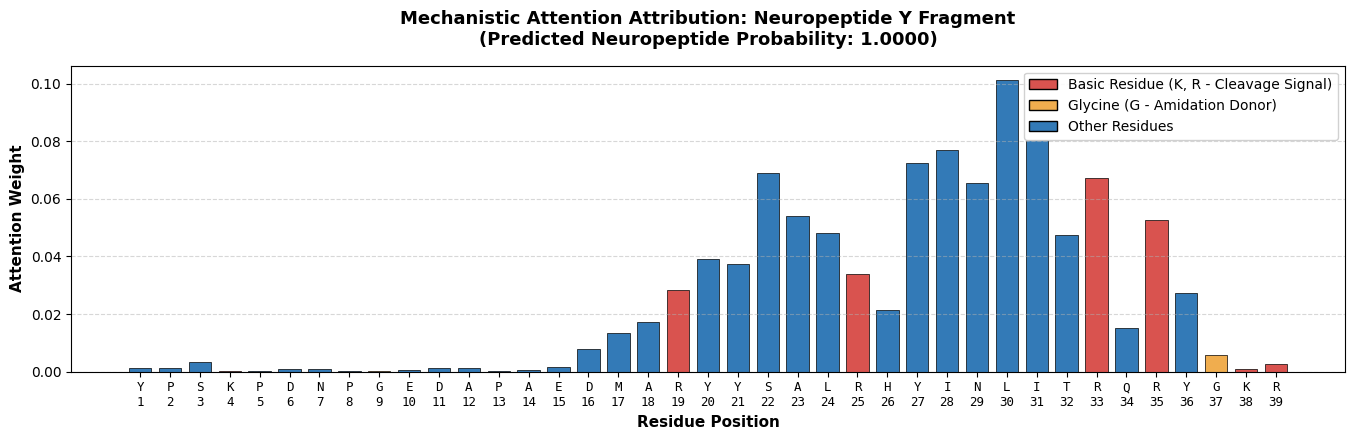

[+] Saved attention plot to: /content/drive/MyDrive/neuropeptide-classifier-benchmark/figures/attention_substance_p_precursor_fragment.png


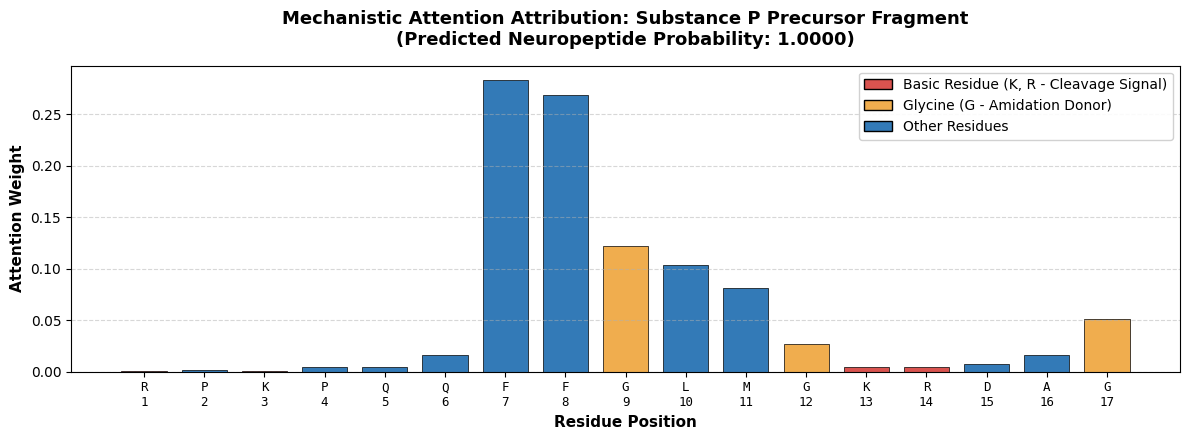

In [ ]:
def plot_attention_profile(
    seq_name: str,
    raw_sequence: str,
    annotated_motifs: list = None,
    save_fig: bool = True,
):
  data = get_sequence_attention(raw_sequence)
  prob = data['predicted_prob']
  attn = data['attention']
  residues = list(raw_sequence)
  positions = np.arange(1, len(residues) + 1)

  plt.figure(figsize=(max(12, len(residues) * 0.35), 4.5))

  # Color bars based on basic cleavage residues (K, R)
  colors = []
  for aa in residues:
    if aa in ['K', 'R']:
      colors.append('#D9534F')  # Red highlight for basic cleavage residues
    elif aa in ['G']:
      colors.append('#F0AD4E')  # Gold highlight for amidation glycine
    else:
      colors.append('#337AB7')  # Blue for background residues

  bars = plt.bar(
      positions,
      attn,
      color=colors,
      width=0.75,
      edgecolor='black',
      linewidth=0.5,
  )

  # Formatting
  plt.title(
      f'Mechanistic Attention Attribution: {seq_name}\n(Predicted Neuropeptide Probability: {prob:.4f})',
      fontsize=13,
      fontweight='bold',
      pad=15,
  )
  plt.xlabel('Residue Position', fontsize=11, fontweight='bold')
  plt.ylabel('Attention Weight', fontsize=11, fontweight='bold')
  plt.xticks(
      positions,
      [f'{aa}\n{i}' for i, aa in enumerate(residues, 1)],
      fontsize=9,
      fontfamily='monospace',
  )
  plt.grid(axis='y', linestyle='--', alpha=0.5)

  # Custom legend
  from matplotlib.patches import Patch

  legend_elements = [
      Patch(
          facecolor='#D9534F',
          edgecolor='black',
          label='Basic Residue (K, R - Cleavage Signal)',
      ),
      Patch(
          facecolor='#F0AD4E',
          edgecolor='black',
          label='Glycine (G - Amidation Donor)',
      ),
      Patch(facecolor='#337AB7', edgecolor='black', label='Other Residues'),
  ]
  plt.legend(handles=legend_elements, loc='upper right', framealpha=0.9)

  plt.tight_layout()
  if save_fig:
    out_file = os.path.join(
        FIGURES_DIR, f'attention_{seq_name.lower().replace(" ", "_")}.png'
    )
    plt.savefig(out_file, dpi=300)
    print(f'[+] Saved attention plot to: {out_file}')
  plt.show()


# Example 1: Human Neuropeptide Y Precursor Fragment (Contains central active peptide + GKR cleavage site)
plot_attention_profile(
    seq_name='Neuropeptide Y Fragment',
    raw_sequence='YPSKPDNPGEDAPAEDMARYYSALRHYINLITRQRYGKR',
)

# Example 2: Substance P / Tachykinin Precursor Fragment
plot_attention_profile(
    seq_name='Substance P Precursor Fragment',
    raw_sequence='RPKPQQFFGLMGKRDAG',
)

In [ ]:
from scipy.stats import mannwhitneyu

# 1. Load the independent test set and isolate positive neuropeptides
test_csv_path = os.path.join(DRIVE_DIR, "Data/test.csv")
test_df = pd.read_csv(test_csv_path)

neuropeptides_test = test_df[test_df["label"] == 1]["seq"].tolist()
print(
    f"[+] Loaded {len(neuropeptides_test)} verified neuropeptides from"
    f" {test_csv_path}"
)

# 2. Define functional amino acid subsets
PHARMACOPHORE_AA = set(
    ["F", "Y", "W", "L", "M"]
)  # Hydrophobic / Aromatic binding residues
CLEAVAGE_AA = set(["K", "R"])  # Prohormone convertase cleavage signals
AMIDATION_AA = set(["G"])  # C-terminal amidation donors

# Containers to collect attention values across all positions
pharmacophore_attn = []
cleavage_attn = []
amidation_attn = []
background_attn = []

# 3. Extract attention distributions across test sequences
eval_sample_size = min(150, len(neuropeptides_test))
print(
    f"[+] Computing attention attribution across {eval_sample_size}"
    " neuropeptides..."
)

for seq in neuropeptides_test[:eval_sample_size]:
  res = get_sequence_attention(seq)
  attn = res["attention"]

  for aa, val in zip(seq, attn):
    if aa in PHARMACOPHORE_AA:
      pharmacophore_attn.append(val)
    elif aa in CLEAVAGE_AA:
      cleavage_attn.append(val)
    elif aa in AMIDATION_AA:
      amidation_attn.append(val)
    else:
      background_attn.append(val)

# Convert to NumPy arrays
pharmacophore_attn = np.array(pharmacophore_attn)
cleavage_attn = np.array(cleavage_attn)
amidation_attn = np.array(amidation_attn)
background_attn = np.array(background_attn)

# 4. Compute quantitative means and enrichment ratios vs. background
mean_pharm = np.mean(pharmacophore_attn)
mean_cleave = np.mean(cleavage_attn)
mean_amid = np.mean(amidation_attn)
mean_bg = np.mean(background_attn)

ratio_pharm = mean_pharm / (mean_bg + 1e-9)
ratio_cleave = mean_cleave / (mean_bg + 1e-9)
ratio_amid = mean_amid / (mean_bg + 1e-9)

# 5. Statistical hypothesis testing (Mann-Whitney U Test, one-sided: category > background)
_, p_pharm = mannwhitneyu(
    pharmacophore_attn, background_attn, alternative="greater"
)
_, p_cleave = mannwhitneyu(
    cleavage_attn, background_attn, alternative="greater"
)
_, p_amid = mannwhitneyu(amidation_attn, background_attn, alternative="greater")

# 6. Format and display the summary table
summary_lines = [
    "=" * 82,
    f"MECHANISTIC ATTENTION ENRICHMENT ANALYSIS (Evaluated on {eval_sample_size} Neuropeptides)",
    "=" * 82,
    f"{'Functional Category':<35} {'Mean Attn':<12} {'Enrichment':<14} {'p-value (MWU)':<15}",
    "-" * 82,
    (
        f"{'Binding Core (F, Y, W, L, M)':<35} {mean_pharm:<12.6f}"
        f" {ratio_pharm:<14.2f}x {p_pharm:<15.3e}"
    ),
    (
        f"{'Cleavage Sites (K, R)':<35} {mean_cleave:<12.6f} {ratio_cleave:<14.2f}x"
        f" {p_cleave:<15.3e}"
    ),
    (
        f"{'Amidation Glycine (G)':<35} {mean_amid:<12.6f} {ratio_amid:<14.2f}x"
        f" {p_amid:<15.3e}"
    ),
    (
        f"{'Background Residues':<35} {mean_bg:<12.6f} {'1.00x (Ref)':<14}"
        f" {'-':<15}"
    ),
    "=" * 82,
]

summary_text = "\n".join(summary_lines)
print(summary_text)

# 7. Export summary report to figures directory
report_path = os.path.join(FIGURES_DIR, "motif_enrichment_stats.txt")
with open(report_path, "w") as f:
  f.write(summary_text)
print(f"\n[+] Statistical report saved to: {report_path}")

[+] Loaded 444 verified neuropeptides from /content/drive/MyDrive/neuropeptide-classifier-benchmark/Data/test.csv
[+] Computing attention attribution across 150 neuropeptides...
MECHANISTIC ATTENTION ENRICHMENT ANALYSIS (Evaluated on 150 Neuropeptides)
Functional Category                 Mean Attn    Enrichment     p-value (MWU)  
----------------------------------------------------------------------------------
Binding Core (F, Y, W, L, M)        0.089344     2.67          x 8.039e-50      
Cleavage Sites (K, R)               0.045642     1.37          x 8.324e-03      
Amidation Glycine (G)               0.060259     1.80          x 1.536e-12      
Background Residues                 0.033425     1.00x (Ref)    -              

[+] Statistical report saved to: /content/drive/MyDrive/neuropeptide-classifier-benchmark/figures/motif_enrichment_stats.txt
